# Mini-Project

**Author**: Varivashya Poladi, Shivey Guttal, Fale Sanyat Vinod

## Objectives

- Gain hands-on experience with the pricing and risk management of vanilla European options using real market data.

- Estimate implied volatility from observed option market prices using the Black–Scholes model and numerical root-finding methods.

- Infer the implied funding rate and dividend yield using the spot–futures parity relationship.

- Construct and manage a delta-hedged portfolio by dynamically rebalancing positions in the underlying asset and cash account.

- Analyze the hedging performance by measuring daily and cumulative hedging errors until option expiry.

- Study the theoretical behavior of delta hedging using Monte Carlo simulations and evaluate risk measures such as Value at Risk (VaR) and Expected Shortfall (ES).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from pathlib import Path

## Part 1: Data Collection and Market Setup

We collect daily market data for a liquid NSE European option (like NIFTY 27-Mar-2025) over the final 10 trading days before expiry. The dataset includes:

- **Spot price** $S(t)$: Current price of the underlying index
- **Futures price** $F(t)$: Price of the futures contract with the same expiry
- **Option market price** $C_{\text{Market}}(t)$: Observed call option premium
- **Strike price** $K$ and **Expiry date** $T$

**Time to maturity** for each trading day is computed as:

$$T - t = \frac{\text{Expiry Date} - \text{Date}}{365}$$

The last 10 trading days are retained to track the option position from initiation to expiry.
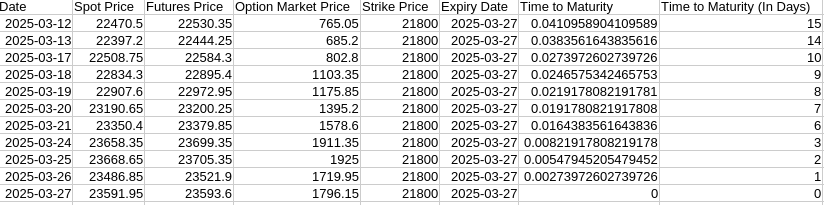

In [2]:
# Load dataset

def load_dataset(path):

    df = pd.read_csv(path)

    df["Date"] = pd.to_datetime(df["Date"])
    df["Expiry Date"] = pd.to_datetime(df["Expiry Date"])

    df = df.sort_values("Date")

    return df


# Keep only last 10 trading days before expiry

def filter_last_10_days(df):

    expiry = df["Expiry Date"].iloc[0]

    df_before_expiry = df[df["Date"] <= expiry]

    return df_before_expiry.tail(11)

In [3]:
data_path = r"output.csv"

## Part 2: Implied Volatility Estimation

### Black–Scholes Pricing Formula

Under the Black–Scholes model (with continuous dividend yield $q$), the price of a European call option is:

$$C = S \, e^{-qT} \, N(d_1) - K \, e^{-rT} \, N(d_2)$$

and the put price is:

$$P = K \, e^{-rT} \, N(-d_2) - S \, e^{-qT} \, N(-d_1)$$

where

$$d_1 = \frac{\ln(S/K) + \left(r - q + \frac{\sigma^2}{2}\right)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

and $N(\cdot)$ is the standard normal CDF.

### Implied Volatility via Bisection

Since there is no closed-form inverse for $\sigma$, we solve for **implied volatility** $\hat{\sigma}$ numerically using the **bisection method**:

$$C_{\text{BS}}(S, K, T, r, \hat{\sigma}, q) = C_{\text{Market}}$$

The bisection method brackets the root in an interval $[\sigma_{\text{low}}, \sigma_{\text{high}}]$ and iteratively halves the interval based on the sign of $C_{\text{BS}} - C_{\text{Market}}$, converging to tolerance $\epsilon = 10^{-6}$.

**Verification:** 
We verify the implied volatity by substituting $\hat{\sigma}$ back into the BS formula. It should ideally recover $C_{\text{Market}}$ up to numerical precision.


In [4]:
# Q2

def black_scholes_d1d2(S, K, T, r, sigma, option='call', q=0):

    if T <= 0 or sigma <= 0:
        return None, None
    
    d1 = (np.log(S/K) + (r - q + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return d1, d2

def black_scholes(S, K, T, r, sigma, option='call', q=0):

    if T <= 0:
        if option == 'call':
            return max(S-K,0)
        else:
            return max(K-S,0)

    d1, d2 = black_scholes_d1d2(S, K, T, r, sigma, option, q)
    
    if d1 is None:
        return max(S - K, 0) if option == 'call' else max(K - S, 0)

    call_price = S*np.exp(-q*T)*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

    if option == 'call':
        return call_price
    else:
        return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1) #call_price - S*np.exp(-q*T) + K*np.exp(-r*T)
    

# Implied olatility via Bisection

def implied_volatility_bisection(C_market, S, K, T, r, q, option='call', low=0.0001, high=3.0, tol=1e-6):

    if T <= 1e-10:
        return np.nan  # IV is undefined at expiry
    
    while high - low > tol:

        mid = (low+high)/2
        price_mid = black_scholes(S,K,T,r,mid,option,q)

        if abs(price_mid - C_market) < tol:
            return mid

        if price_mid > C_market:
            high = mid
        else:
            low = mid

    return mid


# Compute the Implied Volatility (IV).

def compute_implied_volatility(df, r):

    ivs = []

    for _, row in df.iterrows():

        S = row["Spot Price"]
        K = row["Strike Price"]
        T = row["Time to Maturity"]
        C = row["Option Market Price"]

        iv = implied_volatility_bisection(C, S, K, T, r, q=0, option='call', low=0.0001, high=3.0, tol=1e-6)

        ivs.append(iv)

    df["Implied Volatility"] = ivs

    return df


# Verify the Black-Scholes price.

def verify_prices(df, r):
    
    df["BS Price"] = df.apply(
        lambda x: black_scholes(
            x["Spot Price"],
            x["Strike Price"],
            x["Time to Maturity"],
            r,
            x["Implied Volatility"],
            option='call',
            q=0
        ),
        axis=1
    )

    df["Pricing Error"] = df["BS Price"] - df["Option Market Price"]

    return df


# Plot the Option Price.

def plot_option_price(df):

    plt.figure(figsize=(8,5))

    plt.plot(df["Date"], df["Option Market Price"], marker='o')

    plt.title("Option Price Over Time")
    plt.xlabel("Date")
    plt.ylabel("Option Price")

    plt.xticks(rotation=45)
    plt.grid(True)

    plt.show()


# Plot the IV.

def plot_implied_volatility(df):

    plt.figure(figsize=(8,5))
    df = df[(df["Implied Volatility"] < 1.0) & (df["Implied Volatility"] > 0)]
    plt.plot(df["Date"], df["Implied Volatility"], marker='o')

    plt.title("Implied Volatility Over Time")
    plt.xlabel("Date")
    plt.ylabel("Implied Volatility")

    plt.xticks(rotation=45)
    plt.grid(True)

    plt.show()


Verification Table:

         Date  Option Market Price     BS Price  Pricing Error  \
10 2025-03-12               765.05   765.050494       0.000494   
9  2025-03-13               685.20   685.199564      -0.000436   
8  2025-03-17               802.80   802.799603      -0.000397   
7  2025-03-18              1103.35  1103.350310       0.000310   
6  2025-03-19              1175.85  1175.850004       0.000004   
5  2025-03-20              1395.20  1415.720505      20.520505   
4  2025-03-21              1578.60  1578.600007       0.000007   
3  2025-03-24              1911.35  1911.349883      -0.000117   
2  2025-03-25              1925.00  1924.999946      -0.000054   
1  2025-03-26              1719.95  1719.949913      -0.000087   
0  2025-03-27              1796.15  1791.950000      -4.200000   

    Implied Volatility  
10            0.142409  
9             0.133457  
8             0.198912  
7             0.233449  
6             0.264010  
5             0.000101  
4         

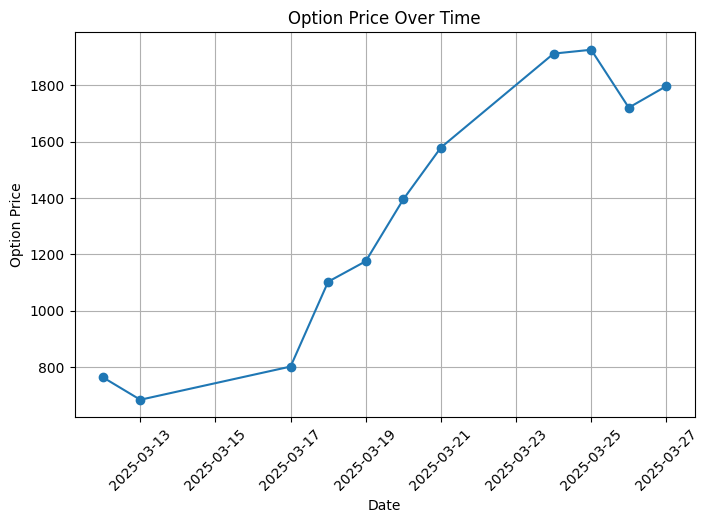

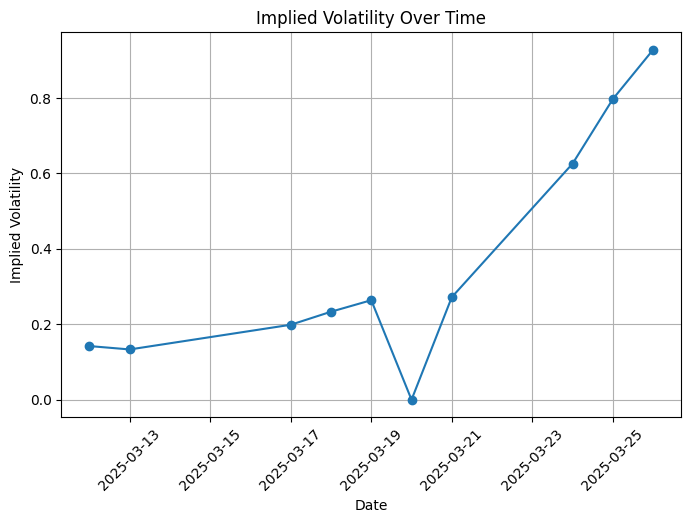

In [5]:
r = 0.06

df_2 = load_dataset(data_path)

df_2 = filter_last_10_days(df_2)

df_2 = compute_implied_volatility(df_2, r)

df_2 = verify_prices(df_2, r)

print("\nVerification Table:\n")

print(df_2[[
    "Date",
    "Option Market Price",
    "BS Price",
    "Pricing Error",
    "Implied Volatility"
]])

plot_option_price(df_2)

plot_implied_volatility(df_2)

## Part 3: Inferring the Implied Funding Rate and Dividend Yield

### Spot–Futures Parity

Under no-arbitrage, the futures price is related to the spot price via:

$$F(t) = S(t) \, e^{(r - q)(T - t)}$$

where $r$ is the risk-free rate and $q$ is the continuous dividend yield of the underlying.

### Implied $(r - q)$

Rearranging, we can extract the implied net carry rate from observed market prices:

$$r - q = \frac{\ln\!\left(F(t) / S(t)\right)}{T - t}$$

Given a proxy for the risk-free rate $r$ (e.g., 6% p.a., the approximate 91-day T-bill rate), the implied dividend yield follows as:

$$q = r - (r - q)$$

This is computed daily and tracked over time to assess the stability of the implied carry.


In [6]:
# Q3

# Compute implied (r - q)

def compute_r_minus_q(df):

    df["r_minus_q"] = np.log(df["Futures Price"] / df["Spot Price"]) / df["Time to Maturity"]

    return df


# Compute implied dividend yield

def compute_dividend_yield(df, r):

    df["Implied Dividend Yield"] = r - df["r_minus_q"]

    return df


# Plot evolution of (r - q)

def plot_r_minus_q(df):

    plt.figure(figsize=(8,5))

    plt.plot(df["Date"], df["r_minus_q"], marker='o')

    plt.title("Implied (r - q) Over Time")
    plt.xlabel("Date")
    plt.ylabel("(r - q)")

    plt.xticks(rotation=45)
    plt.grid(True)

    plt.show()


# Plot dividend yield

def plot_dividend_yield(df):

    plt.figure(figsize=(8,5))

    plt.plot(df["Date"], df["Implied Dividend Yield"], marker='o')

    plt.title("Implied Dividend Yield Over Time")
    plt.xlabel("Date")
    plt.ylabel("Dividend Yield (q)")

    plt.xticks(rotation=45)
    plt.grid(True)

    plt.show()


Spot-Futures Parity Table:

         Date  Spot Price  Futures Price  r_minus_q  Implied Dividend Yield
10 2025-03-12    22470.50       22530.35   0.064725               -0.004725
9  2025-03-13    22397.20       22444.25   0.054711                0.005289
8  2025-03-17    22508.75       22584.30   0.122306               -0.062306
7  2025-03-18    22834.30       22895.40   0.108374               -0.048374
6  2025-03-19    22907.60       22972.95   0.129972               -0.069972
5  2025-03-20    23190.65       23200.25   0.021581                0.038419
4  2025-03-21    23350.40       23379.85   0.076676               -0.016676
3  2025-03-24    23658.35       23699.35   0.210666               -0.150666
2  2025-03-25    23668.65       23705.35   0.282761               -0.222761
1  2025-03-26    23486.85       23521.90   0.544292               -0.484292
0  2025-03-27    23591.95       23593.60        inf                    -inf


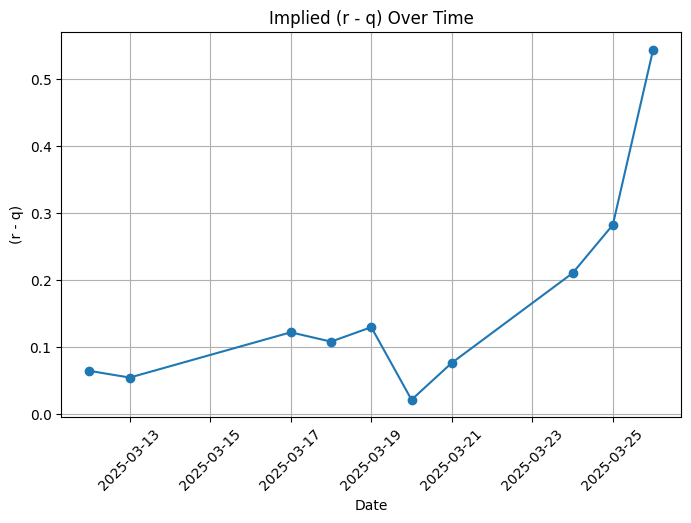

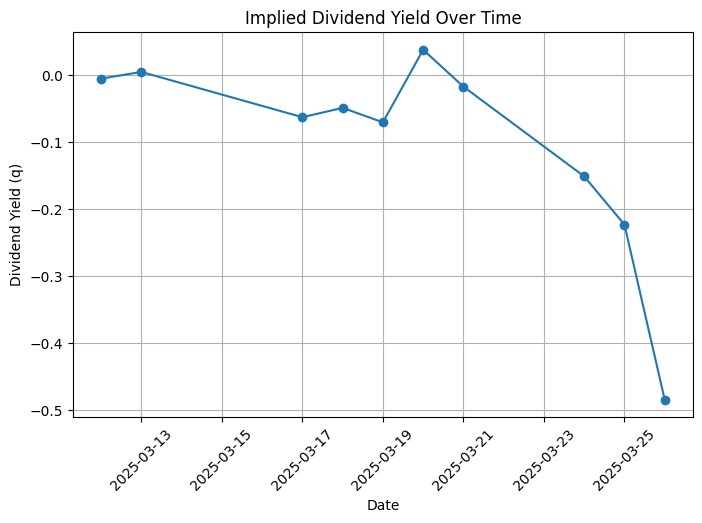

In [7]:
r = 0.06

df_3 = load_dataset(data_path)
df_3 = filter_last_10_days(df_3)

df_3 = compute_r_minus_q(df_3)

df_3 = compute_dividend_yield(df_3, r)

print("\nSpot-Futures Parity Table:\n")

print(df_3[[
    "Date",
    "Spot Price",
    "Futures Price",
    "r_minus_q",
    "Implied Dividend Yield"
]])

plot_r_minus_q(df_3)

plot_dividend_yield(df_3)


## Part 4: Black–Scholes Price Comparison Using Implied Parameters

With the implied volatility $\hat{\sigma}$ (from Part 2) and implied dividend yield $q$ (from Part 3) estimated for each day, we recompute the Black–Scholes call price incorporating the dividend-adjusted cost of carry:

$$C_{\text{BS}}(t) = S(t)\,e^{-q(T-t)}\,N(d_1) - K\,e^{-r(T-t)}\,N(d_2)$$

Plotting $C_{\text{BS}}(t)$ against the observed market price $C_{\text{Market}}(t)$ over the remaining days to expiry validates the consistency of the implied parameters and the model fit.


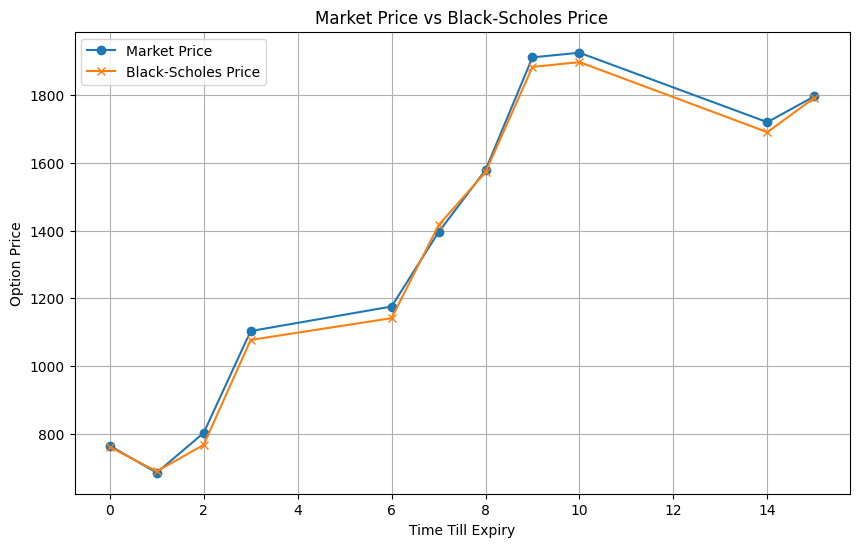

In [8]:
# Q4

df_4 = load_dataset(data_path)
df_4 = filter_last_10_days(df_4)

T = max(df_4['Time to Maturity'])

K = df_4['Strike Price'].values
S = df_4['Spot Price'].values
t = df_4['Time to Maturity'].values
market_prices = df_4['Option Market Price'].values
qs = df_3["Implied Dividend Yield"].values
r = 0.06
implied_vols = [implied_volatility_bisection(market_prices[i], S[i], K[i], t[i], r, qs[i], option='call') for i in range(len(df_4))]

call_prices = [black_scholes(S[i], K[i], t[i], r, implied_vols[i], option='call') for i in range(len(df_4))]
plt.figure(figsize=(10,6))
plt.plot(t[::-1]*365, market_prices, label='Market Price', marker='o')
plt.plot(t[::-1]*365, call_prices, label='Black-Scholes Price', marker='x')
plt.xlabel('Time Till Expiry')
plt.ylabel('Option Price')
plt.title('Market Price vs Black-Scholes Price')
plt.legend()
plt.grid()
plt.show()

## Part 5: Construction of the Delta-Hedged Portfolio

### Black–Scholes Delta

The **delta** of a European call (with dividend yield $q$) is the sensitivity of the option price to the spot price:

$$\Delta_{\text{call}} = e^{-qT} \, N(d_1)$$

It represents the number of units of the underlying to hold to neutralize first-order price risk.

### Self-Financing Portfolio

At each rebalancing date $t_i$, the portfolio consists of:
- **Shares:** $\Delta_i$ units of the underlying, valued at $\Delta_i \cdot S(t_i)$
- **Cash account** $B(t_i)$: earns the risk-free rate $r$, absorbing all trade costs

The **self-financing condition** ensures no external cash injections:

$$B(t_i) = \left(B(t_{i-1}) + \Delta_{t_{i-1}} \cdot S(t_i) \cdot q \cdot \delta t - (\Delta_i - \Delta_{i-1}) \cdot S(t_i)\right) e^{r\,\delta t}$$

where the dividend income $\Delta_{i-1} \cdot S(t_i) \cdot q \cdot \delta t$ is credited to cash.

### Hedging Error

At each step, the **hedging error** measures how closely the replicating portfolio tracks the option liability:

$$\epsilon(t_i) = \underbrace{\Delta_i \cdot S(t_i) + B(t_i)}_{\text{portfolio value}} - C_{\text{Market}}(t_i)$$

At expiry, the option liability is replaced by the intrinsic payoff $\max(S_T - K, 0)$.


[np.float64(0.8831490805957357), np.float64(0.8628151670558286), np.float64(0.9244587543389373), np.float64(0.9637563977581067), np.float64(0.9812364942605571), np.float64(0.9992634607254705), np.float64(0.9984134435598769), np.float64(0.9705714680452153), np.float64(0.9591662595511319), np.float64(1.0013277090835009), 1.0]
Time: 1, Portfolio Value: 11.797262003718743, Market Price: 685.2
Time: 2, Portfolio Value: -12.564680070344139, Market Price: 802.8
Time: 3, Portfolio Value: -19.199577599859822, Market Price: 1103.35
Time: 4, Portfolio Value: -27.488069303120483, Market Price: 1175.85
Time: 5, Portfolio Value: 22.96265155189826, Market Price: 1395.2
Time: 6, Portfolio Value: -1.921847369785155, Market Price: 1578.6
Time: 7, Portfolio Value: -31.7549363608573, Market Price: 1911.35
Time: 8, Portfolio Value: -48.3136640135599, Market Price: 1925.0
Time: 9, Portfolio Value: -34.977574639025306, Market Price: 1719.95
Time: 10, Portfolio Value: -36.6713584031786, Market Price: 1796.15


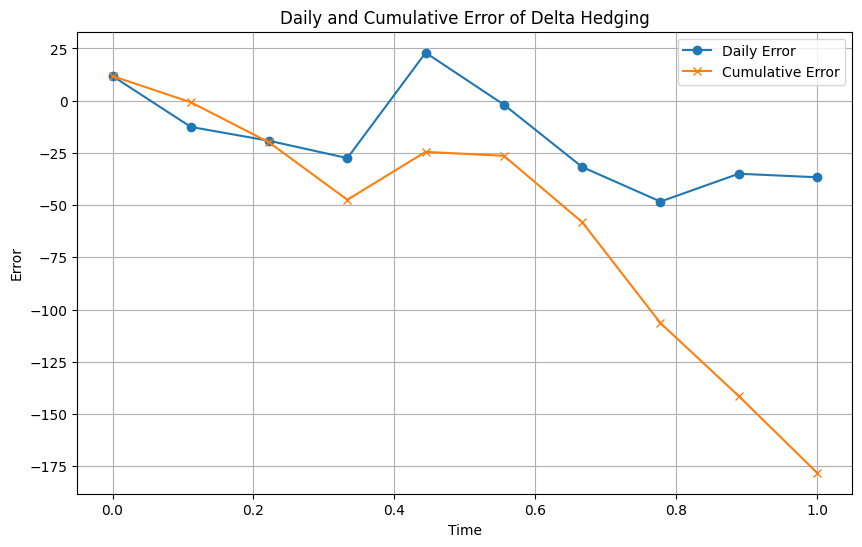

In [9]:
# Q5

def bs_delta(S, K, T, r, q, sigma, option='call'):

    if T <= 1e-10:
        if option == 'call':
            return 1.0 if S > K else (0.5 if S == K else 0.0)
        else:
            return -1.0 if S < K else (-0.5 if S == K else 0.0)
    d1, d2 = black_scholes_d1d2(S, K, T, r, sigma, option, q)
    if d1 is None:
        return 1.0 if (option == 'call' and S > K) else 0.0
    if option == 'call':
        return np.exp(-q * T) * norm.cdf(d1)
    else:
        return np.exp(-q * T) * (norm.cdf(d1) - 1)
    
F = df_4['Futures Price'].values
S = df_4['Spot Price'].values
t = df_4['Time to Maturity'].values

# r_qs = df_3["r_minus_q"].values

qs = df_3["Implied Dividend Yield"].values


df_4['Implied Volatility'] = implied_vols
df_4['Dividend Yield'] = qs


bsdts = [bs_delta(S[i], K[0], t[i], r, qs[i], implied_vols[i], option='call') for i in range(len(S))]
print(bsdts)

dt = 1/365


portfolio_values = []
cash = [0]*len(S)
shares = [0]*len(S)
delta_prev = bsdts[0]
cash[0] = -delta_prev*S[0] +market_prices[0]
shares[0] = delta_prev

for ti in range(1, len(S)):

    trade = bsdts[ti] - delta_prev
    q = qs[ti-1]
    dividend_income = shares[ti-1] * S[ti] * q * dt

    # update cash (self-financing with dividends)
    cash[ti] = (cash[ti-1] + dividend_income - trade*S[ti]) * np.exp(r*dt)

    shares[ti] = bsdts[ti]
    delta_prev = bsdts[ti]

    if ti == len(S)-1:
        payoff = max(S[ti] - K[0], 0)
        # print(payoff, cash[ti], shares[ti]*S[ti])
        portfolio_value = shares[ti]*S[ti] + cash[ti] - payoff
        portfolio_values.append(portfolio_value)
    else:
        portfolio_value = shares[ti]*S[ti] + cash[ti] - market_prices[ti]
        portfolio_values.append(portfolio_value)
    
    bs_price = call_prices[ti]   # Black-Scholes price

    replication = shares[ti]*S[ti] + cash[ti]


    print(f"Time: {ti}, Portfolio Value: {portfolio_value}, Market Price: {market_prices[ti]}")
    
portfolio_values = np.array(portfolio_values)

daily_error = portfolio_values
cumulative_error = np.cumsum(portfolio_values)

plt.figure(figsize=(10,6))
plt.plot(np.linspace(0, 1, len(daily_error)), daily_error, label='Daily Error', marker='o')
plt.plot(np.linspace(0, 1, len(cumulative_error)), cumulative_error, label='Cumulative Error', marker='x')
plt.xlabel('Time')
plt.ylabel('Error')
plt.title('Daily and Cumulative Error of Delta Hedging')
plt.grid()
plt.legend()

## Part 6: Monte Carlo Hedging Experiment

### Geometric Brownian Motion (GBM)

To study the theoretical behavior of delta hedging, we simulate price paths of the underlying using GBM under the risk-neutral measure:

$$dS = (r - q)\,S\,dt + \sigma\,S\,dW_t$$

The discrete log-return increment over a time step $\delta t$ is:

$$\ln\frac{S(t+\delta t)}{S(t)} = \left(r - q - \frac{\sigma^2}{2}\right)\delta t + \sigma\sqrt{\delta t}\,Z, \quad Z \sim N(0,1)$$

The volatility parameter $\sigma$ is set to the implied volatility estimated from market data.

### Terminal Hedging Error Distribution

For each simulated path, the same delta-hedging strategy is applied. The **terminal hedging error** is:

$$\text{Error}_i = \Delta_{N-1} \cdot S_T^{(i)} + B_T^{(i)} - \max(S_T^{(i)} - K,\, 0)$$

Repeating over $N_{\text{sim}} = 10{,}000$ paths gives an empirical distribution of hedging errors. The standard deviation of this distribution $\propto \sigma\sqrt{\delta t}$, so more frequent rebalancing reduces hedging error.

### Value at Risk (VaR) and Expected Shortfall (ES)

From the P&L distribution of the short option position (hedged and unhedged), we compute:

$$\text{VaR}_\alpha = -\text{Quantile}_\alpha(\text{P\&L})$$

$$\text{ES}_\alpha = -\,\mathbb{E}\!\left[\text{P\&L} \;\middle|\; \text{P\&L} \leq \text{Quantile}_\alpha(\text{P\&L})\right]$$

at confidence levels $\alpha \in \{95\%,\, 99\%\}$. ES (also called CVaR) captures the average loss in the worst $1-\alpha$ tail scenarios, making it a more informative risk measure than VaR alone.



Implied vol (day 1) : 0.1495  (14.95%)
Implied vol (median): 0.1400  (14.00%)

Using σ = 0.1495 (14.95%) for GBM simulation
BS price (day 1)    : 592.9000
Market price (day 1): 592.9000
Difference          : 0.000014
MONTE CARLO SIMULATION PARAMETERS
Initial spot S0  : 22119.30
Strike K         : 21800.00
Time to expiry T : 0.065753 years (10 trading days)
Volatility σ     : 0.1495 (14.95%)
Risk-free rate r : 0.0700
Dividend yield q : -0.007103
BS price C0      : 592.9000
Option type      : Call
Num simulations  : 10000
Running Daily (10 steps)... Done. Mean error: 5.7505, Std: 83.3903
Running Half-Daily (20 steps)... Done. Mean error: 7.1747, Std: 59.6082
Running Hourly (62 steps)... Done. Mean error: 7.1910, Std: 34.0229
VALUE AT RISK (VaR) AND EXPECTED SHORTFALL (ES)
Position             Frequency            95% VaR      99% VaR       95% ES       99% ES
Hedged               Daily               137.3470     251.2234     206.5588     319.9415
Hedged               Half-Daily         

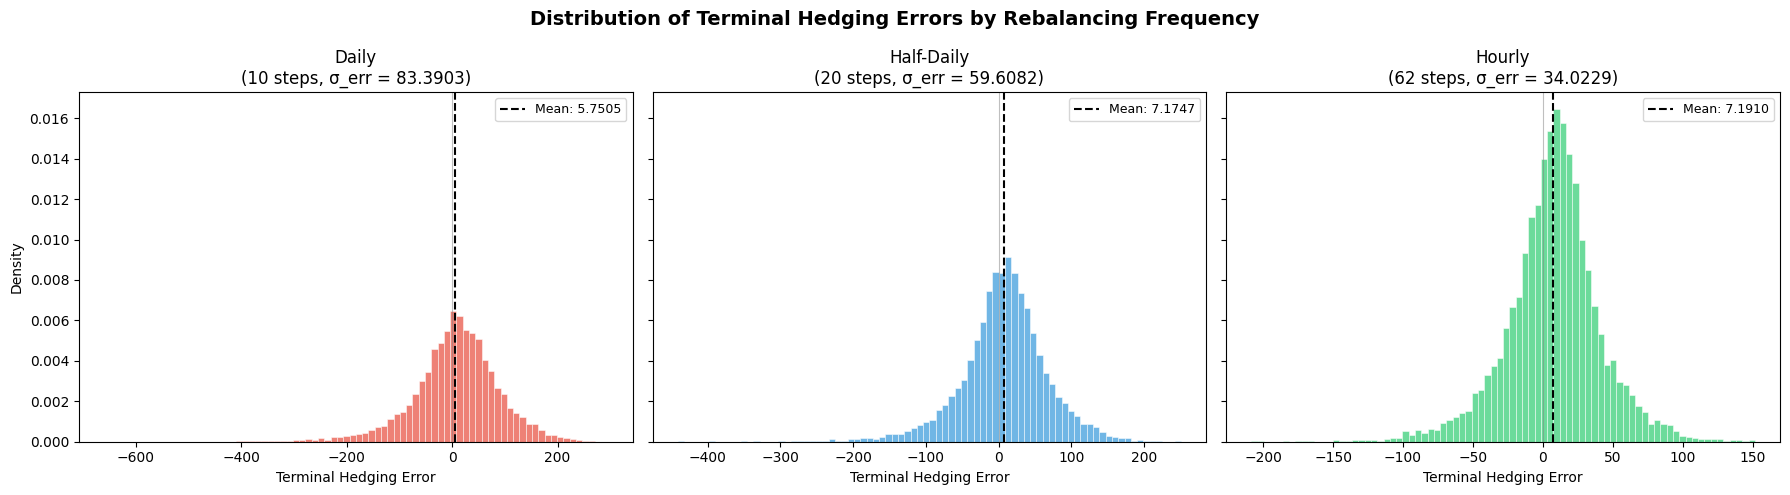

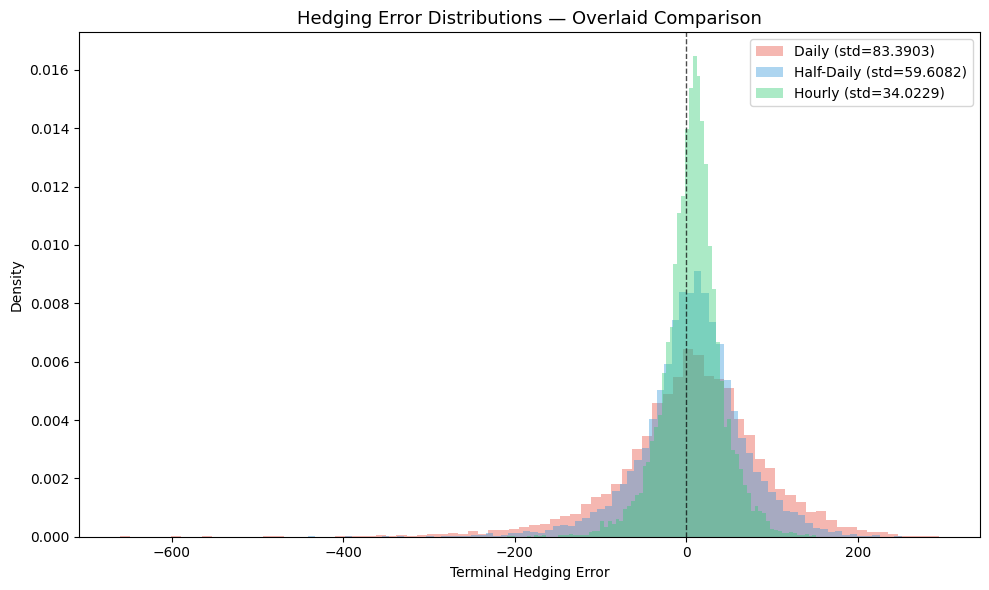

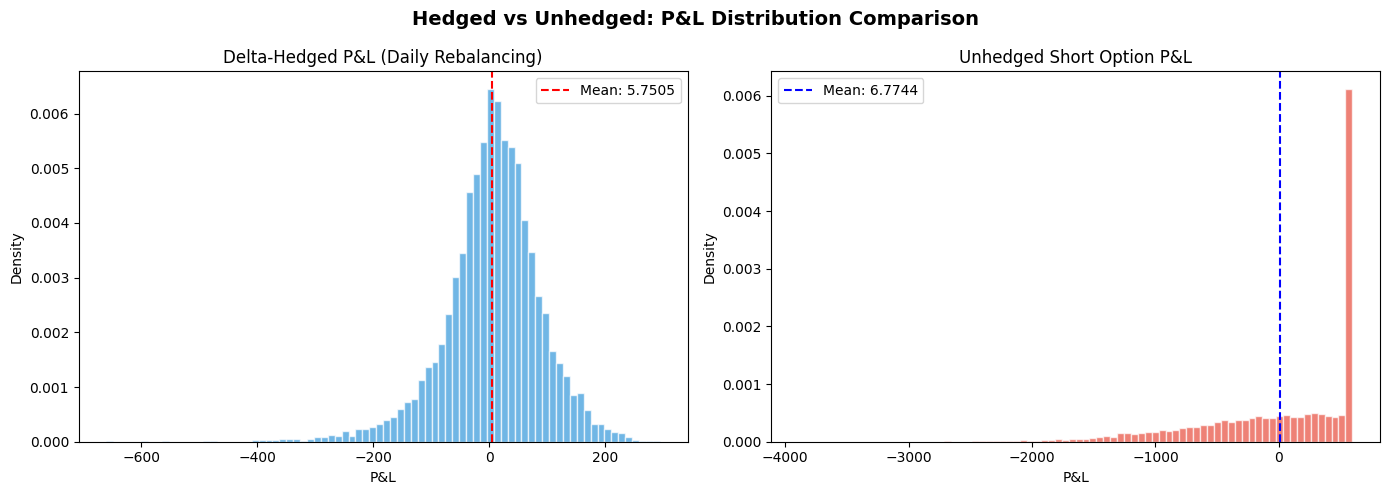

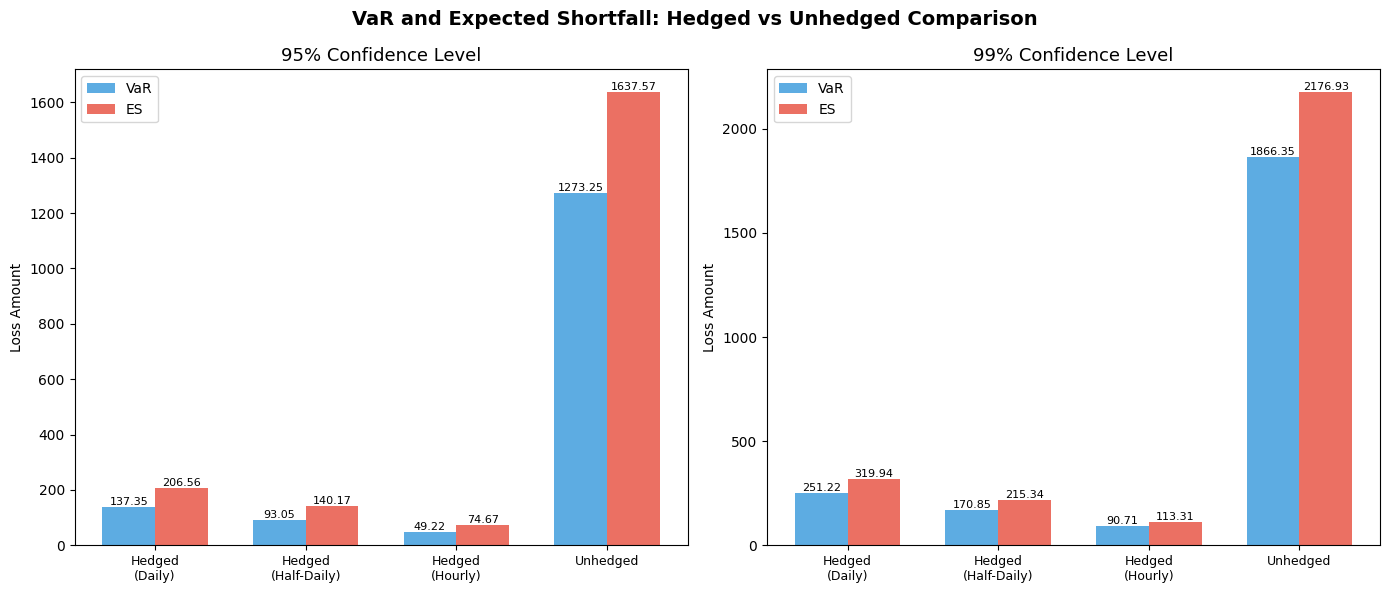

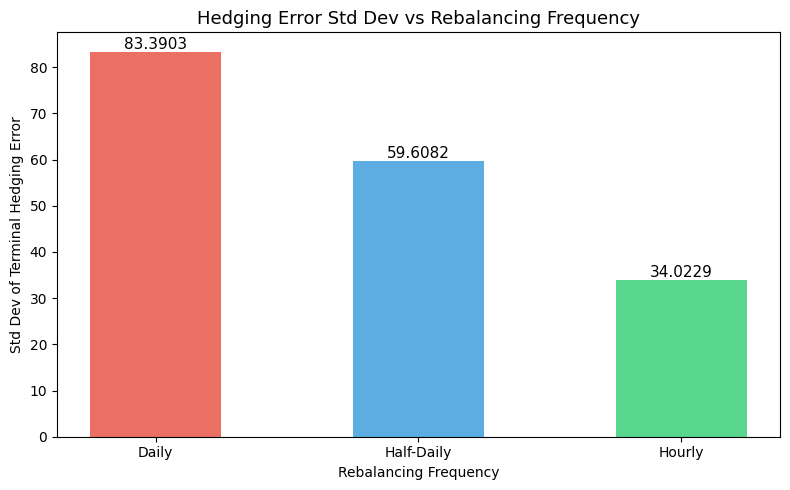

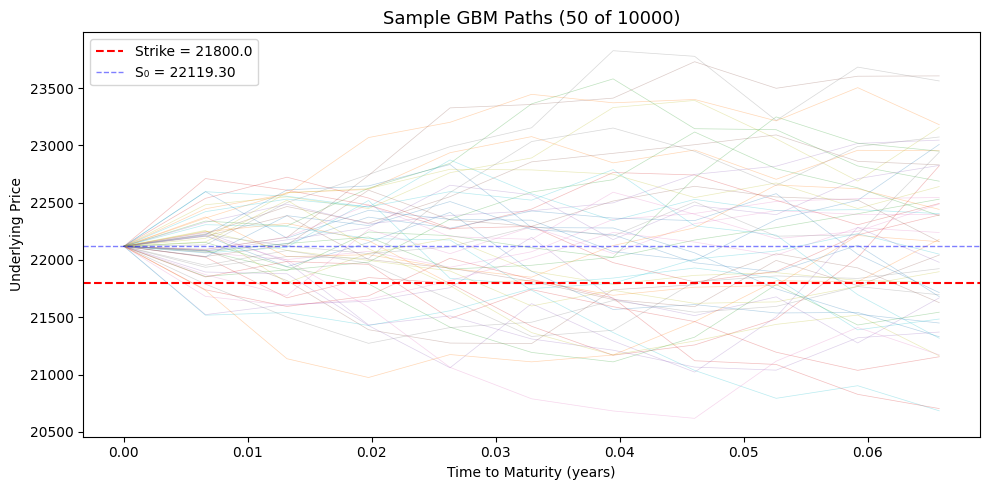

SUMMARY OF RESULTS

Frequency          Steps     Mean Err      Std Err      95% VaR      99% VaR
Daily                 10       5.7505      83.3903     137.3470     251.2234
Half-Daily            20       7.1747      59.6082      93.0464     170.8493
Hourly                62       7.1910      34.0229      49.2240      90.7124
Unhedged             N/A       6.7744     647.5448    1273.2514    1866.3548

Figures saved to: figures
Done!


In [10]:
# Q6

option_type = "CE"
label = "NIFTY 29000 CE (27-Mar-2025)"
lot_size = 75

N_SIMULATIONS = 10000
SEED = 42 # For reproducibility.

# Load the data.

df_6 = pd.read_csv(data_path, parse_dates=["Date", "Expiry Date"])
df_6 = filter_last_10_days(df_6)
df_6 = df_6.sort_values("Date").reset_index(drop=True)
df_6["T"] = (df_6["Expiry Date"] - df_6["Date"]).dt.days / 365.0

# Extract the key scalars from the FIRST trading day (used for simulation).
S0 = df_6["Spot Price"].iloc[0]
K = df_6["Strike Price"].iloc[0]
T_total = df_6["T"].iloc[0]
C0_market = df_6["Option Market Price"].iloc[0]
n_days = len(df_6) - 1 # 10
option = 'call'

def compute_r_minus_q(df):
    
    r_q_values = []
    for _, row in df.iterrows():
        T_rem = row["T"]
        if T_rem > 1e-6:
            r_q = np.log(row["Futures Price"] / row["Spot Price"]) / T_rem
        else:
            r_q = np.nan
        r_q_values.append(r_q)
    df["r_minus_q"] = r_q_values
    return df

df_6 = compute_r_minus_q(df_6)

# Use the median (r - q) as our best estimate — more robust than the mean.

r_minus_q = df_6["r_minus_q"].dropna().median()

# Assume a proxy risk-free rate.

r_proxy = 0.07
q_proxy = r_proxy - r_minus_q

# Compute the IV for each day.

iv_list = []
for _, row in df_6.iterrows():
    iv = implied_volatility_bisection(
        C_market=row["Option Market Price"],
        S=row["Spot Price"], K=K, T=row["T"],
        r=r_proxy, q=q_proxy, option='call'
    )
    iv_list.append(iv)

df_6["Implied Vol"] = iv_list

# Representative implied volatility for GBM simulation

iv_day1 = df_6["Implied Vol"].dropna().iloc[0]
iv_median = df_6["Implied Vol"].dropna().median()

# For deep ITM/OTM options, day-1 IV can be unreliable (near-zero or extremely high).
# because the option price is dominated by intrinsic value with little time value.
# The median IV across all days is more robust.
# We flag and use median if day-1 IV is outside a reasonable range (5%-150%).

if iv_day1 < 0.05 or iv_day1 > 1.5:
    sigma_sim = iv_median
    print(f"\n Day-1 IV ({iv_day1:.4f}) is unreliable (deep ITM/OTM effect).")
    print(f"    Falling back to median IV across all days.")
else:
    sigma_sim = iv_day1

print(f"\nImplied vol (day 1) : {iv_day1:.4f}  ({iv_day1*100:.2f}%)")
print(f"Implied vol (median): {iv_median:.4f}  ({iv_median*100:.2f}%)")
print(f"\nUsing σ = {sigma_sim:.4f} ({sigma_sim*100:.2f}%) for GBM simulation")

C0_bs = black_scholes(S0, K, T_total, r_proxy, sigma_sim, option='call', q=q_proxy)
print(f"BS price (day 1)    : {C0_bs:.4f}")
print(f"Market price (day 1): {C0_market:.4f}")
print(f"Difference          : {abs(C0_bs - C0_market):.6f}")

# Simulations

def simulate_gbm_paths(S0, r, q, sigma, T, n_steps, n_paths, seed=42):
    
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    Z = rng.standard_normal((n_paths, n_steps))

    # Log-price increments: (r - q - σ²/2)*dt + σ*√dt*Z
    drift = (r - q - 0.5 * sigma**2) * dt
    diffusion = sigma * np.sqrt(dt) * Z
    log_increments = drift + diffusion

    log_paths = np.concatenate([
        np.zeros((n_paths, 1)),       
        np.cumsum(log_increments, axis=1)
    ], axis=1)

    paths = S0 * np.exp(log_paths)   
    return paths, dt


def delta_hedge_simulation(paths, dt, S0, K, T, r, q, sigma, option='call'):
    
    n_paths, n_steps_plus_1 = paths.shape
    n_steps = n_steps_plus_1 - 1

    C0 = black_scholes(S0, K, T, r, sigma, option='call', q=q)

    hedging_errors = np.zeros(n_paths)
    unhedged_pnl = np.zeros(n_paths)

    for i in range(n_paths):
        S_path = paths[i]

        T_rem = T                           # Time remaining
        delta = bs_delta(S_path[0], K, T_rem, r, q, sigma, option='call')
        cash = C0 - delta * S_path[0]       # Premium received - cost of shares

        for t in range(1, n_steps):
            cash *= np.exp(r * dt)

            # New time remaining
            T_rem = T - t * dt

            new_delta = bs_delta(S_path[t], K, T_rem, r, q, sigma, option='call')

            # Rebalance: buy (new_delta - delta) shares at current price
            cash -= (new_delta - delta) * S_path[t]
            delta = new_delta

        cash *= np.exp(r * dt)  # Final period interest

        portfolio_value = delta * S_path[-1] + cash

        if option == 'call':
            payoff = max(S_path[-1] - K, 0)
        else:
            payoff = max(K - S_path[-1], 0)

        hedging_errors[i] = portfolio_value - payoff

        unhedged_pnl[i] = C0 * np.exp(r * T) - payoff

    return hedging_errors, unhedged_pnl


# Define rebalancing frequencies
TRADING_HOURS_PER_DAY = 6.25

frequencies = {
    "Daily":     n_days,                                        
    "Half-Daily": n_days * 2,                                   
    "Hourly":    int(n_days * TRADING_HOURS_PER_DAY),           
}


print(f"MONTE CARLO SIMULATION PARAMETERS")
print(f"Initial spot S0  : {S0:.2f}")
print(f"Strike K         : {K:.2f}")
print(f"Time to expiry T : {T_total:.6f} years ({n_days} trading days)")
print(f"Volatility σ     : {sigma_sim:.4f} ({sigma_sim*100:.2f}%)")
print(f"Risk-free rate r : {r_proxy:.4f}")
print(f"Dividend yield q : {q_proxy:.6f}")
print(f"BS price C0      : {C0_bs:.4f}")
print(f"Option type      : {'Call' if option == 'call' else 'Put'}")
print(f"Num simulations  : {N_SIMULATIONS}")


results = {}

for freq_name, n_steps in frequencies.items():
    print(f"Running {freq_name} ({n_steps} steps)...", end=" ")

    paths, dt = simulate_gbm_paths(
        S0, r_proxy, q_proxy, sigma_sim, T_total, n_steps, N_SIMULATIONS, seed=SEED
    )

    hedge_err, unhedged = delta_hedge_simulation(
        paths, dt, S0, K, T_total, r_proxy, q_proxy, sigma_sim, option='call'
    )

    results[freq_name] = {
        "hedging_errors": hedge_err,
        "unhedged_pnl": unhedged,
        "n_steps": n_steps,
        "dt": dt,
        "paths": paths, 
    }

    print(f"Done. Mean error: {hedge_err.mean():.4f}, Std: {hedge_err.std():.4f}")


# VaR and ES

def compute_var_es(pnl_array, confidence_levels=[0.95, 0.99]):

    risk_metrics = {}
    for alpha in confidence_levels:
        quantile_level = 1 - alpha  
        var_quantile = np.percentile(pnl_array, quantile_level * 100)
        var_loss = -var_quantile      

        tail = pnl_array[pnl_array <= var_quantile]
        es_loss = -tail.mean() if len(tail) > 0 else var_loss

        risk_metrics[alpha] = {"VaR": var_loss, "ES": es_loss}
    return risk_metrics

print(f"VALUE AT RISK (VaR) AND EXPECTED SHORTFALL (ES)")

print(f"{'Position':<20} {'Frequency':<15} {'95% VaR':>12} {'99% VaR':>12} {'95% ES':>12} {'99% ES':>12}")


risk_results = {}

for freq_name, res in results.items():
    hedged_risk = compute_var_es(res["hedging_errors"])
    risk_results[f"Hedged ({freq_name})"] = hedged_risk

    print(f"{'Hedged':<20} {freq_name:<15} "
          f"{hedged_risk[0.95]['VaR']:>12.4f} {hedged_risk[0.99]['VaR']:>12.4f} "
          f"{hedged_risk[0.95]['ES']:>12.4f} {hedged_risk[0.99]['ES']:>12.4f}")

    if freq_name == "Daily":  # Only compute once; unhedged doesn't depend on frequency
        unhedged_risk = compute_var_es(res["unhedged_pnl"])
        risk_results["Unhedged"] = unhedged_risk


unhedged_r = risk_results["Unhedged"]
print(f"{'Unhedged (short)':<20} {'N/A':<15} "
      f"{unhedged_r[0.95]['VaR']:>12.4f} {unhedged_r[0.99]['VaR']:>12.4f} "
      f"{unhedged_r[0.95]['ES']:>12.4f} {unhedged_r[0.99]['ES']:>12.4f}")
print(f"\nNote: Positive values represent potential losses.")
print(f"      VaR = max loss at given confidence level")
print(f"      ES  = average loss in the worst tail scenarios")


fig_dir = Path(data_path).parent / "figures"
fig_dir.mkdir(exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
fig.suptitle("Distribution of Terminal Hedging Errors by Rebalancing Frequency",
             fontsize=14, fontweight="bold")

colors = {"Daily": "#e74c3c", "Half-Daily": "#3498db", "Hourly": "#2ecc71"}

for ax, (freq_name, res) in zip(axes, results.items()):
    errors = res["hedging_errors"]
    ax.hist(errors, bins=80, density=True, alpha=0.7, color=colors[freq_name],
            edgecolor="white", linewidth=0.5)
    ax.axvline(errors.mean(), color="black", linestyle="--", linewidth=1.5,
               label=f"Mean: {errors.mean():.4f}")
    ax.axvline(0, color="gray", linestyle="-", linewidth=0.8, alpha=0.5)
    ax.set_title(f"{freq_name}\n({res['n_steps']} steps, σ_err = {errors.std():.4f})")
    ax.set_xlabel("Terminal Hedging Error")
    ax.legend(fontsize=9)

axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(10, 6))
for freq_name, res in results.items():
    errors = res["hedging_errors"]
    ax.hist(errors, bins=80, density=True, alpha=0.4, color=colors[freq_name],
            label=f"{freq_name} (std={errors.std():.4f})")

ax.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.7)
ax.set_title("Hedging Error Distributions — Overlaid Comparison", fontsize=13)
ax.set_xlabel("Terminal Hedging Error")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Hedged (using Daily as example)
hedged = results["Daily"]["hedging_errors"]
axes[0].hist(hedged, bins=80, density=True, alpha=0.7, color="#3498db", edgecolor="white")
axes[0].axvline(hedged.mean(), color="red", linestyle="--", label=f"Mean: {hedged.mean():.4f}")
axes[0].set_title("Delta-Hedged P&L (Daily Rebalancing)")
axes[0].set_xlabel("P&L")
axes[0].set_ylabel("Density")
axes[0].legend()

# Unhedged
unhedged = results["Daily"]["unhedged_pnl"]
axes[1].hist(unhedged, bins=80, density=True, alpha=0.7, color="#e74c3c", edgecolor="white")
axes[1].axvline(unhedged.mean(), color="blue", linestyle="--", label=f"Mean: {unhedged.mean():.4f}")
axes[1].set_title("Unhedged Short Option P&L")
axes[1].set_xlabel("P&L")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.suptitle("Hedged vs Unhedged: P&L Distribution Comparison", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


# VaR and ES comparison

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for idx, alpha in enumerate([0.95, 0.99]):
    ax = axes[idx]
    labels, var_vals, es_vals = [], [], []

    for freq_name in frequencies:
        key = f"Hedged ({freq_name})"
        labels.append(f"Hedged\n({freq_name})")
        var_vals.append(risk_results[key][alpha]["VaR"])
        es_vals.append(risk_results[key][alpha]["ES"])

    labels.append("Unhedged")
    var_vals.append(risk_results["Unhedged"][alpha]["VaR"])
    es_vals.append(risk_results["Unhedged"][alpha]["ES"])

    x = np.arange(len(labels))
    width = 0.35

    bars1 = ax.bar(x - width/2, var_vals, width, label="VaR", color="#3498db", alpha=0.8)
    bars2 = ax.bar(x + width/2, es_vals, width, label="ES", color="#e74c3c", alpha=0.8)

    ax.set_title(f"{int(alpha*100)}% Confidence Level", fontsize=13)
    ax.set_ylabel("Loss Amount")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=9)
    ax.legend()

    for bar in bars1:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f"{bar.get_height():.2f}", ha="center", va="bottom", fontsize=8)
    for bar in bars2:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f"{bar.get_height():.2f}", ha="center", va="bottom", fontsize=8)

plt.suptitle("VaR and Expected Shortfall: Hedged vs Unhedged Comparison",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


# Std. Deviation

freq_labels = list(frequencies.keys())
stds = [results[f]["hedging_errors"].std() for f in freq_labels]
steps = [frequencies[f] for f in freq_labels]

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(freq_labels, stds, color=["#e74c3c", "#3498db", "#2ecc71"], alpha=0.8, width=0.5)
for i, (lbl, s) in enumerate(zip(freq_labels, stds)):
    ax.text(i, s, f"{s:.4f}", ha="center", va="bottom", fontsize=11)
ax.set_title("Hedging Error Std Dev vs Rebalancing Frequency", fontsize=13)
ax.set_ylabel("Std Dev of Terminal Hedging Error")
ax.set_xlabel("Rebalancing Frequency")
plt.tight_layout()
plt.show()


# Sample simulations of GBM.

fig, ax = plt.subplots(figsize=(10, 5))
sample_paths = results["Daily"]["paths"][:50]
time_grid = np.linspace(0, T_total, n_days + 1)

for path in sample_paths:
    ax.plot(time_grid, path, alpha=0.3, linewidth=0.5)

ax.axhline(K, color="red", linestyle="--", linewidth=1.5, label=f"Strike = {K}")
ax.axhline(S0, color="blue", linestyle="--", linewidth=1, alpha=0.5, label=f"S₀ = {S0:.2f}")
ax.set_title(f"Sample GBM Paths (50 of {N_SIMULATIONS})", fontsize=13)
ax.set_xlabel("Time to Maturity (years)")
ax.set_ylabel("Underlying Price")
ax.legend()
plt.tight_layout()
plt.show()

# Summary

print(f"SUMMARY OF RESULTS")

print(f"\n{'Frequency':<15} {'Steps':>8} {'Mean Err':>12} {'Std Err':>12} {'95% VaR':>12} {'99% VaR':>12}")

for freq_name, res in results.items():
    e = res["hedging_errors"]
    rk = risk_results[f"Hedged ({freq_name})"]
    print(f"{freq_name:<15} {res['n_steps']:>8d} {e.mean():>12.4f} {e.std():>12.4f} "
          f"{rk[0.95]['VaR']:>12.4f} {rk[0.99]['VaR']:>12.4f}")


print(f"{'Unhedged':<15} {'N/A':>8} {results['Daily']['unhedged_pnl'].mean():>12.4f} "
      f"{results['Daily']['unhedged_pnl'].std():>12.4f} "
      f"{risk_results['Unhedged'][0.95]['VaR']:>12.4f} "
      f"{risk_results['Unhedged'][0.99]['VaR']:>12.4f}")
print(f"\nFigures saved to: {fig_dir}")
print("Done!")

Daily with TC → Mean: -12.4183, Std: 86.2313
Half-Daily with TC → Mean: -19.5361, Std: 63.2495
Hourly with TC → Mean: -41.3777, Std: 43.0155


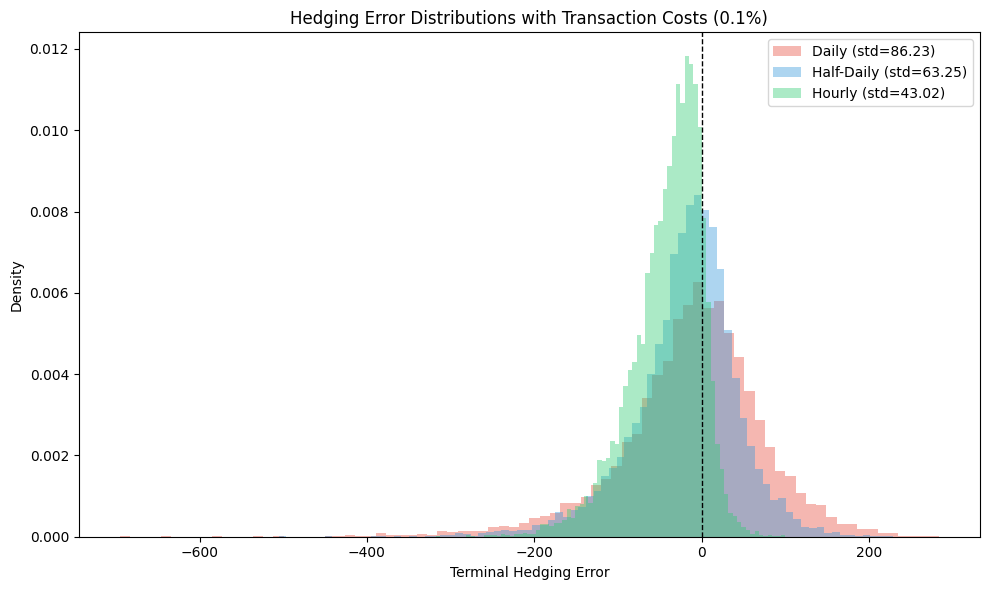

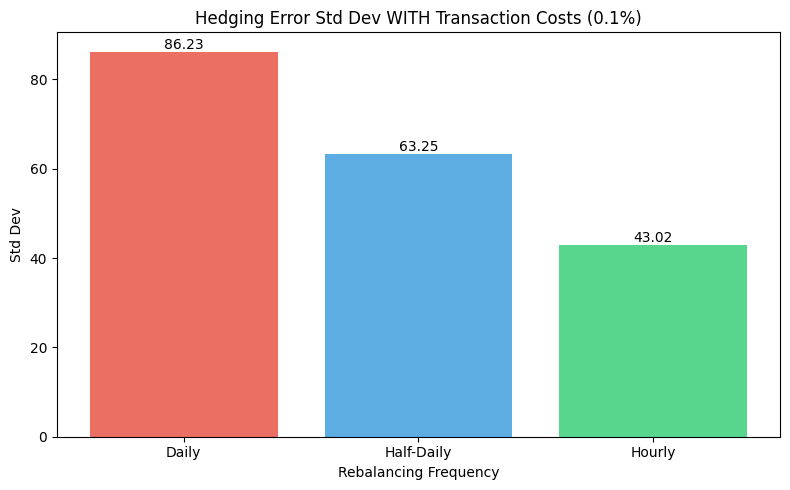

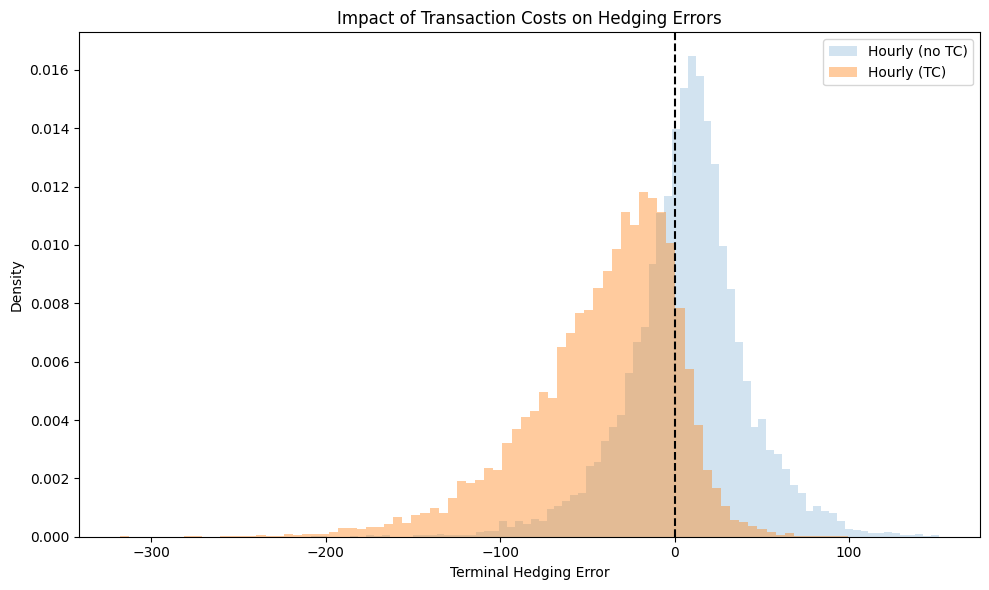

In [11]:
def delta_hedge_with_costs(paths, dt, S0, K, T, r, q, sigma, 
                          option='call', tc=0.001):

    n_paths, n_steps_plus_1 = paths.shape
    n_steps = n_steps_plus_1 - 1

    C0 = black_scholes(S0, K, T, r, sigma, option='call', q=q)

    hedging_errors = np.zeros(n_paths)

    for i in range(n_paths):
        S_path = paths[i]

        T_rem = T
        delta = bs_delta(S_path[0], K, T_rem, r, q, sigma, option='call')

        cash = C0 - delta * S_path[0]

        for t in range(1, n_steps):

            cash *= np.exp(r * dt)

            T_rem = T - t * dt
            new_delta = bs_delta(S_path[t], K, T_rem, r, q, sigma, option='call')

            trade = new_delta - delta

            #  TRANSACTION COST
            cost = tc * abs(trade) * S_path[t]

            # Update cash
            cash -= trade * S_path[t] + cost

            delta = new_delta

        cash *= np.exp(r * dt)

        portfolio_value = delta * S_path[-1] + cash

        payoff = max(S_path[-1] - K, 0) if option == 'call' else max(K - S_path[-1], 0)

        hedging_errors[i] = portfolio_value - payoff

    return hedging_errors
results_tc = {}

for freq_name, n_steps in frequencies.items():

    paths, dt = simulate_gbm_paths(
        S0, r_proxy, q_proxy, sigma_sim, T_total, n_steps, N_SIMULATIONS, seed=SEED
    )

    hedge_err_tc = delta_hedge_with_costs(
        paths, dt, S0, K, T_total, r_proxy, q_proxy, sigma_sim,
        option='call', tc=0.001   # 0.1%
    )

    results_tc[freq_name] = hedge_err_tc

    print(f"{freq_name} with TC → Mean: {hedge_err_tc.mean():.4f}, Std: {hedge_err_tc.std():.4f}")

# Plot: Hedging error distributions with transaction costs
fig, ax = plt.subplots(figsize=(10, 6))

colors = {"Daily":"#e74c3c", "Half-Daily": "#3498db", "Hourly": "#2ecc71"}

for freq_name in frequencies:
    errors = results_tc[freq_name]

    ax.hist(errors, bins=80, density=True, alpha=0.4,
            color=colors[freq_name],
            label=f"{freq_name} (std={errors.std():.2f})")

ax.axvline(0, color="black", linestyle="--", linewidth=1)

ax.set_title("Hedging Error Distributions with Transaction Costs (0.1%)")
ax.set_xlabel("Terminal Hedging Error")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.show()

# Plot: Std of hedging error with transaction costs
freq_labels = list(frequencies.keys())
stds_tc = [results_tc[f].std() for f in freq_labels]

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(freq_labels, stds_tc,
       color=["#e74c3c", "#3498db", "#2ecc71"], alpha=0.8)

for i, s in enumerate(stds_tc):
    ax.text(i, s, f"{s:.2f}", ha="center", va="bottom")

ax.set_title("Hedging Error Std Dev WITH Transaction Costs (0.1%)")
ax.set_ylabel("Std Dev")
ax.set_xlabel("Rebalancing Frequency")

plt.tight_layout()
plt.show()

#Comparison of std with and without transaction costs
fig, ax = plt.subplots(figsize=(10, 6))
err_no_tc = results['Hourly']["hedging_errors"]
err_tc = results_tc['Hourly']

ax.hist(err_no_tc, bins=80, density=True, alpha=0.2,
        label=f"{'Hourly'} (no TC)")

ax.hist(err_tc, bins=80, density=True, alpha=0.4,
        label=f"{'Hourly'} (TC)")

ax.axvline(0, color="black", linestyle="--")

ax.set_title("Impact of Transaction Costs on Hedging Errors")
ax.set_xlabel("Terminal Hedging Error")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.show()